<a href="https://colab.research.google.com/github/asiddiqha/rag-huggingface-docs/blob/main/Embeddings_Semantic_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Embeddings, Similarity Metrics and Semantic Search

In this notebook I work through how text becomes vectors, how I compare those vectors, and how that turns into semantic search: the retrieval step behind my RAG project.

**What I cover**
1. What embeddings are and why I need them
2. Sentence embeddings with `all-MiniLM-L6-v2`
3. Similarity matrix and semantic search
4. Visualising embeddings with PCA
5. Cosine vs dot product vs Euclidean vs Manhattan, and why rankings can flip
6. Normalisation: when dot product equals cosine
7. Bi-encoder vs cross-encoder, and dense vs sparse search
8. Choosing an embedding model (local vs hosted)

**Runs on:** Google Colab, CPU is enough. The Jina API cell is optional.

## 1. Setup

In [1]:
!pip install -q sentence-transformers scikit-learn plotly rank_bm25

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, manhattan_distances

warnings.filterwarnings("ignore")

## 2. What embeddings are

An embedding turns text into a vector of numbers so that **meaning becomes geometry**: texts with similar meaning end up close together, unrelated texts end up far apart. The model learns these positions so that the relationships between words are preserved. The classic example is `king − man + woman ≈ queen`.

Two levels I need to keep apart:
- **Token embeddings:** one vector per token (what BERT produces internally).
- **Sentence or chunk embeddings:** one vector for the whole text, usually by pooling the token vectors. This is what I store in a vector DB for RAG.

**Why I need them:** keyword search only matches exact words. Embeddings let me do **semantic search** and **semantic similarity**: "kitten on a rug" matches "cat on a mat" with no shared keywords.

## 3. Generate sentence embeddings

I use `all-MiniLM-L6-v2`: 384 dimensions, about 90 MB, fast on CPU and good enough for learning and small projects. A bigger model like `all-mpnet-base-v2` (768 dimensions) gives better quality, but it's slower and doubles the storage per vector, which I don't need here.

In [3]:
model = SentenceTransformer("all-MiniLM-L6-v2")
print(f"Embedding dimension: {model.get_sentence_embedding_dimension()}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dimension: 384


In [4]:
sentences = [
    "The cat sits on the mat",
    "A dog plays in the park",
    "The kitten rests on the rug",
    "Python is a programming language",
    "Machine learning is fascinating",
]

embeddings = model.encode(sentences)

print(f"Embedding matrix shape: {embeddings.shape}")  # (5 sentences, 384 dimensions)
print(f"First 10 values of S1: {embeddings[0][:10]}")

Embedding matrix shape: (5, 384)
First 10 values of S1: [ 0.13489069 -0.03206337 -0.02033524  0.035901   -0.02833308  0.04150213
  0.03315878  0.03660566  0.00861659  0.03763953]


Each sentence is now a point in 384-dimensional space. The individual numbers mean nothing by themselves; only the distances and angles between vectors carry meaning.

## 4. Compare sentence similarity

I compare every pair with cosine similarity.

In [5]:
similarity_matrix = cosine_similarity(embeddings)

for i, sentence in enumerate(sentences):
    print(f"\n{sentence}")
    for j, other in enumerate(sentences):
        if i != j:
            print(f"  vs. {other}: {similarity_matrix[i, j]:.3f}")


The cat sits on the mat
  vs. A dog plays in the park: 0.152
  vs. The kitten rests on the rug: 0.664
  vs. Python is a programming language: 0.032
  vs. Machine learning is fascinating: -0.065

A dog plays in the park
  vs. The cat sits on the mat: 0.152
  vs. The kitten rests on the rug: 0.102
  vs. Python is a programming language: 0.112
  vs. Machine learning is fascinating: 0.045

The kitten rests on the rug
  vs. The cat sits on the mat: 0.664
  vs. A dog plays in the park: 0.102
  vs. Python is a programming language: 0.034
  vs. Machine learning is fascinating: -0.092

Python is a programming language
  vs. The cat sits on the mat: 0.032
  vs. A dog plays in the park: 0.112
  vs. The kitten rests on the rug: 0.034
  vs. Machine learning is fascinating: 0.207

Machine learning is fascinating
  vs. The cat sits on the mat: -0.065
  vs. A dog plays in the park: 0.045
  vs. The kitten rests on the rug: -0.092
  vs. Python is a programming language: 0.207


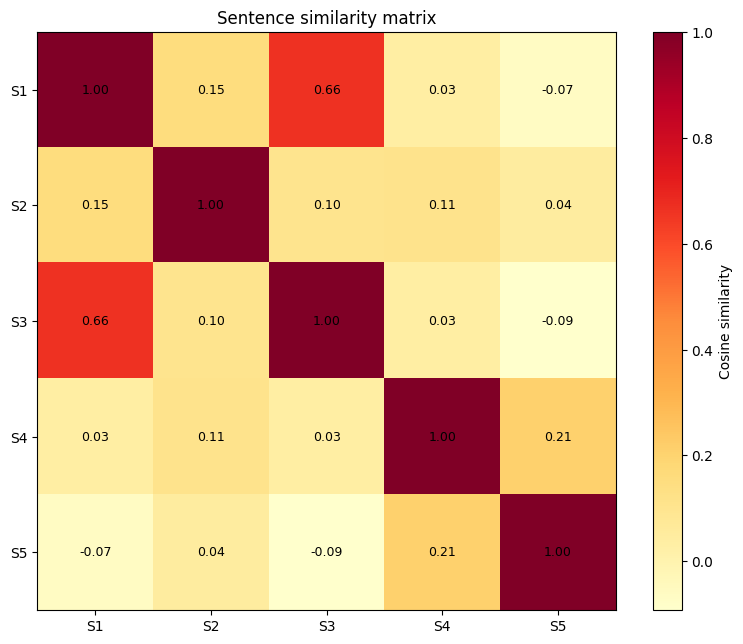

S1: The cat sits on the mat
S2: A dog plays in the park
S3: The kitten rests on the rug
S4: Python is a programming language
S5: Machine learning is fascinating


In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(similarity_matrix, cmap="YlOrRd")

labels = [f"S{i + 1}" for i in range(len(sentences))]
ax.set_xticks(range(len(sentences)), labels=labels)
ax.set_yticks(range(len(sentences)), labels=labels)
plt.colorbar(image, ax=ax, label="Cosine similarity")

for i in range(len(sentences)):
    for j in range(len(sentences)):
        ax.text(j, i, f"{similarity_matrix[i, j]:.2f}", ha="center", va="center", fontsize=9)

ax.set_title("Sentence similarity matrix")
plt.tight_layout()
plt.show()

for label, sentence in zip(labels, sentences):
    print(f"{label}: {sentence}")

**What I observed:**
- Cat on the mat vs kitten on the rug: **0.66**, the highest pair, with almost no shared words.
- Python vs machine learning: **0.21**, the same "tech" topic.
- Cat vs machine learning: **−0.07**, unrelated. Cosine can go negative when vectors point in opposite directions.

## 5. Semantic search

Semantic search is just: embed the query, compare it with every stored embedding, return the top k.

In [7]:
def semantic_search(query, texts, text_embeddings, top_k=3):
    # Encode the query with the SAME model used for the texts, otherwise the vectors aren't comparable
    query_embedding = model.encode([query])
    scores = cosine_similarity(query_embedding, text_embeddings)[0]
    top_indices = scores.argsort()[::-1][:top_k]

    print(f"Query: {query}\n")
    for rank, idx in enumerate(top_indices, start=1):
        print(f"{rank}. {texts[idx]}  (similarity: {scores[idx]:.3f})")
    return top_indices


_ = semantic_search("A small cat on a carpet", sentences, embeddings)

Query: A small cat on a carpet

1. The cat sits on the mat  (similarity: 0.603)
2. The kitten rests on the rug  (similarity: 0.599)
3. A dog plays in the park  (similarity: 0.139)


"Carpet" never appears in my sentences, yet both cat sentences score about 0.60 and the dog sentence only 0.14. The model knows that carpet ≈ rug ≈ mat. Keyword search would have found nothing.

### A small document collection

Same idea on more documents. In a real RAG system, these would be chunks stored in a vector DB, embedded once offline.

In [8]:
documents = [
    "Machine learning models learn patterns from data",
    "Deep neural networks have multiple layers",
    "Natural language processing analyzes text",
    "Computer vision processes images and videos",
    "The cat jumped over the fence",
    "Dogs are loyal and friendly pets",
    "Python is great for data science",
    "JavaScript runs in web browsers",
    "The weather is sunny today",
    "Climate change affects global temperatures",
]

doc_embeddings = model.encode(documents)  # done once and stored; only the query is embedded at search time
_ = semantic_search("How do AI systems learn?", documents, doc_embeddings, top_k=4)

Query: How do AI systems learn?

1. Machine learning models learn patterns from data  (similarity: 0.525)
2. Deep neural networks have multiple layers  (similarity: 0.295)
3. Computer vision processes images and videos  (similarity: 0.272)
4. Natural language processing analyzes text  (similarity: 0.178)


The machine learning document wins clearly (about 0.53), and the next three are all AI topics. The question shares only one word ("learn") with the top answer, so this is matching by meaning.

## 6. Visualise embeddings with PCA

I can't plot 384 dimensions, so I project them down to 2D and 3D with PCA. I use PCA **only for looking**: search always runs on the full vectors, because the projection throws information away.

Variance kept in 2D: 68.3%


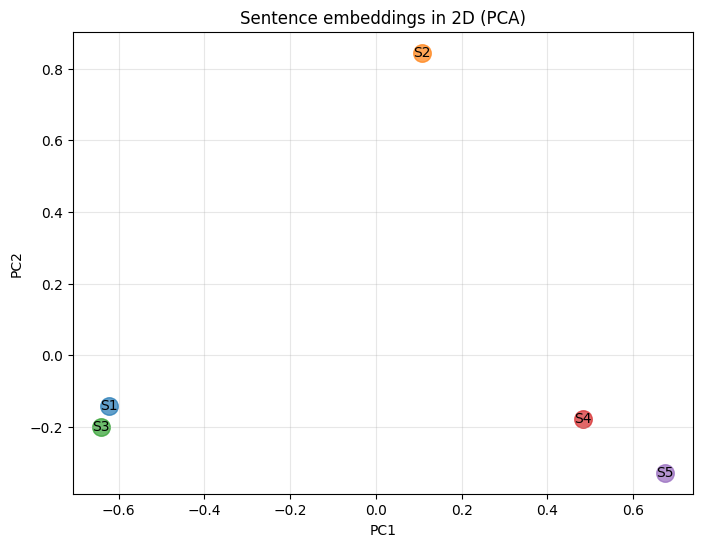

In [9]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)
print(f"Variance kept in 2D: {pca.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(8, 6))
for label, (x, y) in zip(labels, embeddings_2d):
    plt.scatter(x, y, s=160, alpha=0.7)
    plt.annotate(label, (x, y), ha="center", va="center")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Sentence embeddings in 2D (PCA)")
plt.grid(alpha=0.3)
plt.show()

2D keeps about 68% of the variance. That's enough to see the cat and kitten sentences sit together and the two tech sentences form their own group, but not enough to trust exact distances.

In [10]:
pca_3d = PCA(n_components=3)
embeddings_3d = pca_3d.fit_transform(embeddings)

fig = go.Figure(go.Scatter3d(
    x=embeddings_3d[:, 0], y=embeddings_3d[:, 1], z=embeddings_3d[:, 2],
    mode="markers+text",
    text=labels,
    hovertext=sentences,
    hoverinfo="text",
    marker=dict(size=8, color=list(range(len(sentences))), colorscale="Viridis"),
))
fig.update_layout(title="Sentence embeddings in 3D (hover for the sentence)", height=550,
                  scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"))
fig.show()

## 7. Similarity metrics: which one and why

| Metric | Formula | Better when | Looks at |
|---|---|---|---|
| Cosine similarity | A·B / (‖A‖ ‖B‖) | higher | direction only |
| Dot product | Σ AᵢBᵢ | higher | direction **and** length |
| Euclidean (L2) | √Σ(Aᵢ − Bᵢ)² | lower | straight-line distance |
| Manhattan (L1) | Σ\|Aᵢ − Bᵢ\| | lower | grid distance, per dimension |

To build intuition I use three tiny made-up vectors: two berries and a vegetable.

In [11]:
strawberry = np.array([[4, 0, 1]])
blueberry = np.array([[3, 0, 1]])
broccoli = np.array([[8, 2, 9]])

pairs = {"Strawberry vs Blueberry": blueberry, "Strawberry vs Broccoli": broccoli}

rows = []
for name, other in pairs.items():
    rows.append({
        "Pair": name,
        "Cosine (↑)": round(cosine_similarity(strawberry, other)[0, 0], 4),
        "Dot product (↑)": int(np.dot(strawberry[0], other[0])),
        "Euclidean (↓)": round(euclidean_distances(strawberry, other)[0, 0], 4),
        "Manhattan (↓)": round(manhattan_distances(strawberry, other)[0, 0], 4),
    })

pd.DataFrame(rows).set_index("Pair")

,Cosine (↑),Dot product (↑),Euclidean (↓),Manhattan (↓)
Pair,,,,
Strawberry vs Blueberry,0.9971,13,1.0000,1.0
Strawberry vs Broccoli,0.8146,41,9.1652,14.0


**The trap I wanted to verify after class:** for dot product, *higher* means more similar, not lower. But here the dot product says broccoli (41) is more similar to strawberry than blueberry (13) is. Every other metric says blueberry.

That happens because broccoli's vector is much longer, and dot product rewards length as well as direction. Cosine divides the lengths out, so it only measures the angle, which is what carries meaning.

The sign matters too: a negative dot product means the vectors point in opposite directions.

In [12]:
print("Same direction:     [4,0,1] · [3,0,1]   =", np.dot([4, 0, 1], [3, 0, 1]))
print("Opposite direction: [4,0,1] · [-3,0,-1] =", np.dot([4, 0, 1], [-3, 0, -1]))

Same direction:     [4,0,1] · [3,0,1]   = 13
Opposite direction: [4,0,1] · [-3,0,-1] = -13


### Rankings can flip: a cleaner example

Which of `B1 = [800, 0]` and `B2 = [400, 1]` is closer to `A = [1, 1]`?

In [13]:
A = np.array([1, 1])
candidates = {"B1 [800, 0]": np.array([800, 0]), "B2 [400, 1]": np.array([400, 1])}

for name, B in candidates.items():
    dot = np.dot(A, B)
    cos = dot / (np.linalg.norm(A) * np.linalg.norm(B))
    angle = np.degrees(np.arccos(cos))
    print(f"{name}: dot = {dot:>4},  cosine = {cos:.4f},  angle to A = {angle:.2f}°")

B1 [800, 0]: dot =  800,  cosine = 0.7071,  angle to A = 45.00°
B2 [400, 1]: dot =  401,  cosine = 0.7089,  angle to A = 44.86°


- **Dot product** ranks B1 first (800 vs 401), only because B1 is twice as long.
- **Cosine** ranks B2 first (0.7089 vs 0.7071): B2 is tilted very slightly towards A (44.86° vs 45°).

Same data, opposite rankings. In a RAG system, that would change which chunks reach the LLM.

**Pitfalls of the other two metrics:**
- **Euclidean** depends on magnitude and works well in low dimensions. In high dimensions all points start to look about equally far apart (the curse of dimensionality). On normalised vectors it gives the same ranking as cosine.
- **Manhattan** is cheap to compute, but it treats each dimension separately and misses diagonal relationships, so it's a poor fit for dense embeddings.

**Which one I use:**
- **Semantic embeddings (RAG, SBERT, OpenAI-style models):** cosine, because meaning lives in the direction.
- **Recommenders or matrix factorisation:** sometimes dot product, because length can carry useful signal like popularity or confidence.

## 8. Normalisation: when dot product equals cosine

If I scale every vector to length 1, the denominator in cosine becomes 1, so cosine and dot product become the same number.

In [14]:
strawberry_unit = strawberry / np.linalg.norm(strawberry)
blueberry_unit = blueberry / np.linalg.norm(blueberry)

cos_unit = cosine_similarity(strawberry_unit, blueberry_unit)[0, 0]
dot_unit = np.dot(strawberry_unit[0], blueberry_unit[0])

print(f"Length after normalising: {np.linalg.norm(strawberry_unit):.4f}")
print(f"Cosine: {cos_unit:.6f}")
print(f"Dot:    {dot_unit:.6f}")

Length after normalising: 1.0000
Cosine: 0.997054
Dot:    0.997054


In [15]:
# The same with a real model: ask Sentence Transformers for unit-length vectors
unit_embeddings = model.encode(sentences, normalize_embeddings=True)

print("Vector lengths:", np.linalg.norm(unit_embeddings, axis=1).round(4))
print("Dot product equals cosine:", np.allclose(unit_embeddings @ unit_embeddings.T, cosine_similarity(unit_embeddings)))

Vector lengths: [1. 1. 1. 1. 1.]
Dot product equals cosine: True


**Why this matters in practice:** a dot product is cheaper than cosine (no division), so vector databases normalise the vectors once and then use the fast dot product. In my RAG project I set `normalize_embeddings=True` for bge and `hnsw:space: cosine` in ChromaDB for exactly this reason.

## 9. Bi-encoder vs cross-encoder

| | Bi-encoder | Cross-encoder |
|---|---|---|
| How it works | Query and document are embedded **separately**, then compared with cosine | `[CLS] query [SEP] document` goes through the transformer **together**, then a classifier head outputs a relevance score |
| Speed | Fast: documents are embedded once, offline, and indexed | Slow: must run the model once per (query, document) pair |
| Accuracy | Good | Higher: it sees every word interaction between query and document |
| Use for | **Retrieval** over millions of chunks | **Reranking** the top 20 to 50 candidates |

So I use both: the bi-encoder finds candidates fast, then the cross-encoder picks the best few. That's the two-stage retrieval in my RAG pipeline.

In [16]:
query = "How do AI systems learn?"

# Stage 1: bi-encoder retrieval (fast, approximate)
candidate_ids = semantic_search(query, documents, doc_embeddings, top_k=5)

# Stage 2: cross-encoder reranking (slower, more precise) on the candidates only
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
pairs = [(query, documents[i]) for i in candidate_ids]
rerank_scores = reranker.predict(pairs)

print("\nAfter reranking:")
for rank, j in enumerate(np.argsort(rerank_scores)[::-1], start=1):
    print(f"{rank}. {pairs[j][1]}  (relevance: {rerank_scores[j]:.2f})")

Query: How do AI systems learn?

1. Machine learning models learn patterns from data  (similarity: 0.525)
2. Deep neural networks have multiple layers  (similarity: 0.295)
3. Computer vision processes images and videos  (similarity: 0.272)
4. Natural language processing analyzes text  (similarity: 0.178)
5. Python is great for data science  (similarity: 0.108)


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]


After reranking:
1. Machine learning models learn patterns from data  (relevance: -7.38)
2. Computer vision processes images and videos  (relevance: -10.75)
3. Natural language processing analyzes text  (relevance: -10.89)
4. Deep neural networks have multiple layers  (relevance: -11.12)
5. Python is great for data science  (relevance: -11.24)


The cross-encoder's scores are raw relevance logits, not cosine values, so only their order matters.

### Dense vs sparse search

- **Dense (embeddings):** matches meaning and synonyms, but can miss exact terms like product codes, error IDs or rare names.
- **Sparse (BM25, keyword):** matches exact tokens and needs no model, but misses synonyms.

Most production RAG uses **hybrid search** (both, then merged) and then a reranker. Here is the difference on a query that uses synonyms:

In [17]:
from rank_bm25 import BM25Okapi

query = "A small cat on a carpet"
bm25 = BM25Okapi([s.lower().split() for s in sentences])
bm25_scores = bm25.get_scores(query.lower().split())
dense_scores = cosine_similarity(model.encode([query]), embeddings)[0]

pd.DataFrame({"Sentence": sentences, "BM25 (keywords)": bm25_scores.round(3),
              "Dense (cosine)": dense_scores.round(3)})

,Sentence,BM25 (keywords),Dense (cosine)
0,The cat sits on the mat,1.367,0.603
1,A dog plays in the park,0.641,0.139
2,The kitten rests on the rug,0.320,0.599
3,Python is a programming language,0.696,0.134
4,Machine learning is fascinating,0.000,0.013


BM25 finds "The cat sits on the mat" through the word "cat", but then ranks "Python is a programming language" (it shares "a") **above** the kitten-on-the-rug sentence, which only shares "on". It has no idea that kitten ≈ cat or rug ≈ carpet. Dense search puts both cat sentences clearly on top.

## 10. Choosing an embedding model

**Open-source, run locally** (Sentence Transformers)
- Documents never leave my infrastructure, which matters for confidential data.
- Can be **fine-tuned** on domain data. Example: in banking, "SWIFT" means the payment network, not a bird or a car, and a general model may not know that.
- I pay for compute instead of per call.

**Closed-source, via API** (OpenAI, Jina, Cohere)
- No infrastructure to run, often strong quality out of the box.
- But my text is sent to a third party, and usually I can't fine-tune.

**Common open-source sentence embedding models**

| Model | Dimensions | Note |
|---|---|---|
| `all-MiniLM-L6-v2` | 384 | small and fast; good default for prototypes |
| `all-mpnet-base-v2` | 768 | better quality, slower |
| `multi-qa-mpnet-base-dot-v1` | 768 | trained for question-answer search and scored with **dot product**: always use the metric the model was trained for |

**How I evaluate the choice:** build a test set of sentence pairs labelled relevant, irrelevant or opposite (or queries with known correct chunks), then compare models on recall@k for retrieval.

In [18]:
# Local model: runs on my machine, no API key
texts = [
    "Human rights are fundamental freedoms.",
    "Every person deserves equal treatment.",
    "The weather is sunny today.",
]

local_embeddings = model.encode(texts, normalize_embeddings=True)
print(f"Local all-MiniLM-L6-v2: {local_embeddings.shape}")
print("Similarity matrix:\n", (local_embeddings @ local_embeddings.T).round(3))

Local all-MiniLM-L6-v2: (3, 384)
Similarity matrix:
 [[ 1.     0.302 -0.002]
 [ 0.302  1.     0.01 ]
 [-0.002  0.01   1.   ]]


In [19]:
# Hosted model (optional): Jina AI embeddings API
# Add a free key in Colab → key Secrets as JINA_API_KEY and turn on notebook access; otherwise this cell skips itself.
import requests

try:
    from google.colab import userdata
    jina_api_key = userdata.get("JINA_API_KEY")
except Exception:
    jina_api_key = None

if jina_api_key:
    response = requests.post(
        "https://api.jina.ai/v1/embeddings",
        headers={"Authorization": f"Bearer {jina_api_key}"},
        json={"model": "jina-embeddings-v3", "input": texts},
        timeout=30,
    )
    response.raise_for_status()
    jina_embeddings = np.array([item["embedding"] for item in response.json()["data"]])
    jina_embeddings /= np.linalg.norm(jina_embeddings, axis=1, keepdims=True)

    print(f"Hosted jina-embeddings-v3: {jina_embeddings.shape}")
    print("Similarity matrix:\n", (jina_embeddings @ jina_embeddings.T).round(3))
else:
    print("No JINA_API_KEY found, so I skipped the hosted demo.")

Hosted jina-embeddings-v3: (3, 1024)
Similarity matrix:
 [[1.    0.612 0.338]
 [0.612 1.    0.448]
 [0.338 0.448 1.   ]]


Both models put the two human-rights sentences close together and the weather sentence far away. The dimensions differ, so I can never mix vectors from two models in one index: switching the embedding model means re-embedding every document.

## Key takeaways

1. Embeddings turn meaning into geometry; semantic search is nearest-neighbour search in that space.
2. For text embeddings I use **cosine**, or **dot product on normalised vectors**, which is the same ranking and faster.
3. Raw dot product rewards vector length, so rankings can flip ([800, 0] vs [400, 1]).
4. Query and documents must be embedded with the **same model**.
5. Retrieval = bi-encoder (fast); reranking = cross-encoder (accurate); production RAG often adds BM25 for exact terms (hybrid search).
6. Pick a model on privacy, cost, domain fit and a labelled evaluation, not on leaderboard rank alone.